# ABC Company Employee Data Analysis




## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

## 2. Load the Dataset

In [3]:
df = pd.read_csv("ABC Company Dataset.csv")
display(df.head())
print("Dataset shape:", df.shape)
df.info()

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,06-Feb,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,06-Jun,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,06-May,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,06-May,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,06-Oct,231,NaN,5000000.0


Dataset shape: (458, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 458 entries, 0 to 457
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      458 non-null    object 
 1   Team      458 non-null    object 
 2   Number    458 non-null    int64  
 3   Position  458 non-null    object 
 4   Age       458 non-null    int64  
 5   Height    458 non-null    object 
 6   Weight    458 non-null    int64  
 7   College   374 non-null    object 
 8   Salary    447 non-null    float64
dtypes: float64(1), int64(3), object(5)
memory usage: 32.3+ KB


## 3. Preprocessing


In [4]:
np.random.seed(42)
df["Height"] = np.random.randint(150, 181, size=len(df))

print("Missing values:")
display(df.isnull().sum())
display(df.head())

Missing values:


,0
Name,0
Team,0
Number,0
Position,0
Age,0
Height,0
Weight,0
College,84
Salary,11


,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,156,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,169,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,178,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,164,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,160,231,NaN,5000000.0


## 4. Employee Distribution by Team
Count employees in each team and calculate each team's percentage of the total.

,Employee Count,Percentage
Team,,
New Orleans Pelicans,19,4.15
Memphis Grizzlies,18,3.93
Utah Jazz,16,3.49
Milwaukee Bucks,16,3.49
New York Knicks,16,3.49
Boston Celtics,15,3.28
Los Angeles Clippers,15,3.28
Los Angeles Lakers,15,3.28
Phoenix Suns,15,3.28


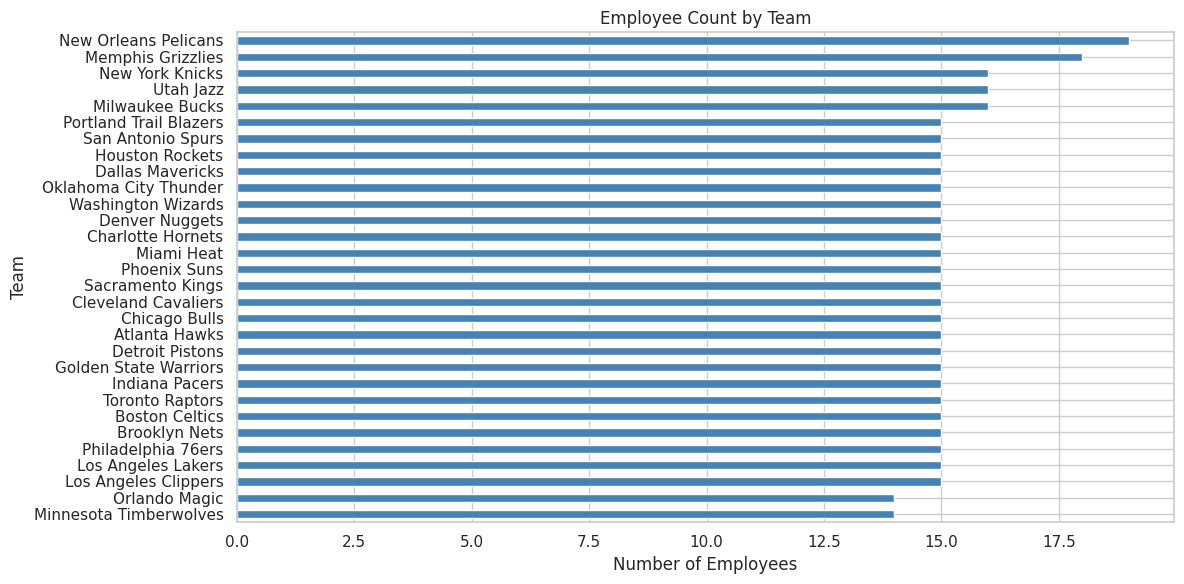

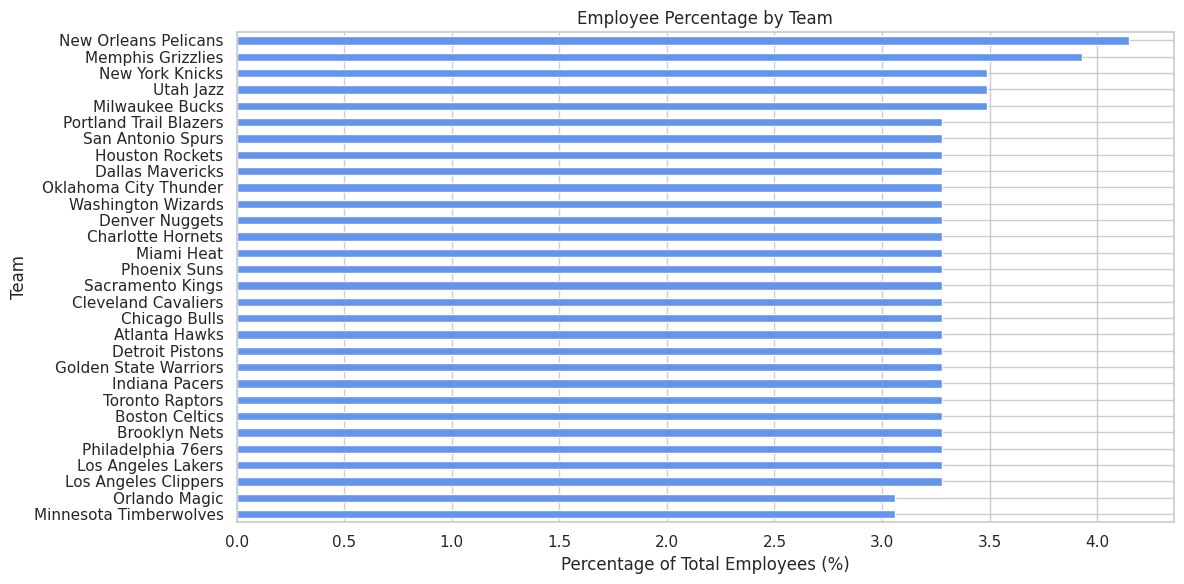

In [5]:
team_count = df["Team"].value_counts()
team_percentage = (team_count / len(df) * 100).round(2)
team_summary = pd.DataFrame({"Employee Count": team_count, "Percentage": team_percentage})
display(team_summary)

team_summary["Employee Count"].sort_values().plot(kind="barh", color="steelblue")
plt.title("Employee Count by Team")
plt.xlabel("Number of Employees")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

team_summary["Percentage"].sort_values().plot(kind="barh", color="cornflowerblue")
plt.title("Employee Percentage by Team")
plt.xlabel("Percentage of Total Employees (%)")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

## 5. Employee Segregation by Position
Count employees in each position and visualize the distribution.

,count
Position,
SG,102
PF,100
PG,92
SF,85
C,79


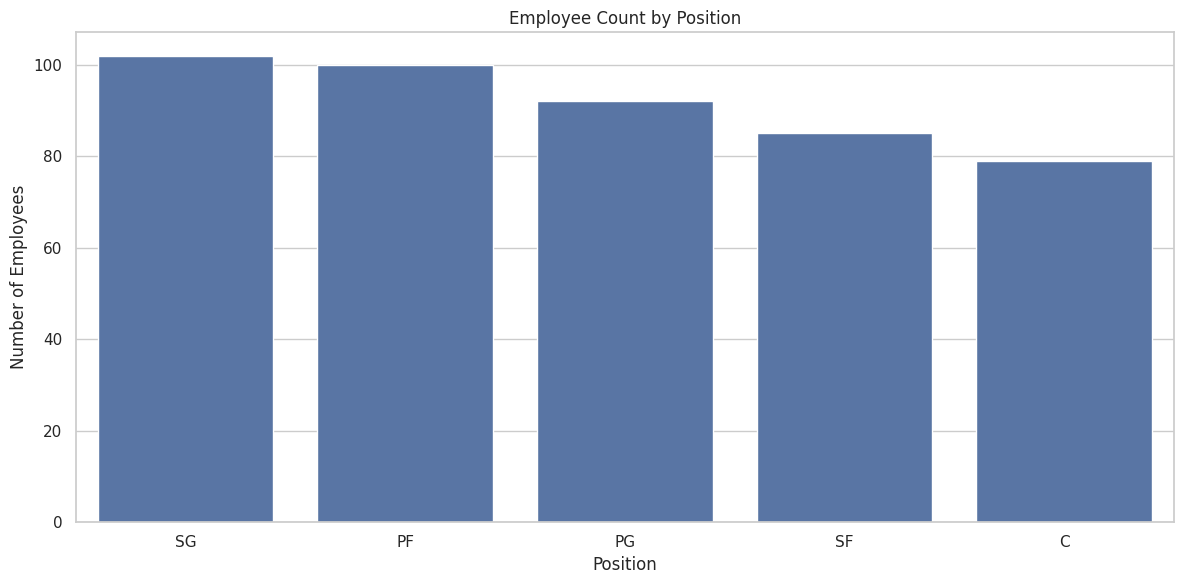

In [6]:
position_count = df["Position"].value_counts()
display(position_count)

sns.barplot(x=position_count.index, y=position_count.values)
plt.title("Employee Count by Position")
plt.xlabel("Position")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

## 6. Predominant Age Group
Group employees into age ranges and identify the age group with the highest count.

,count
Age Group,
18-21,40
22-25,160
26-29,136
30-33,80
34-37,33
38-41,9


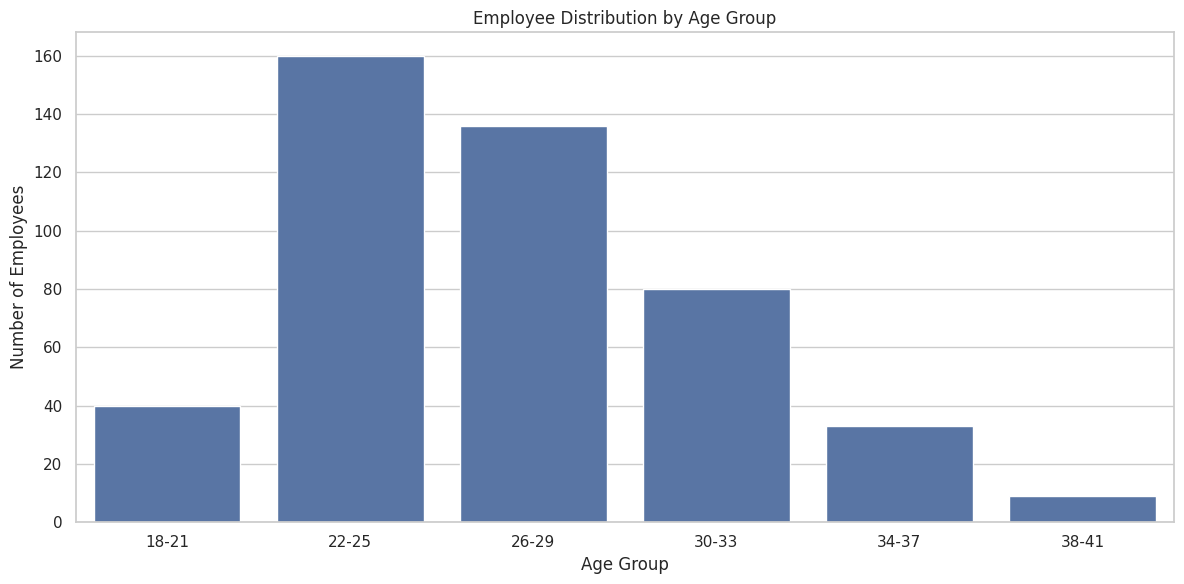

In [7]:
age_bins = [18, 22, 26, 30, 34, 38, 42]
age_labels = ["18-21", "22-25", "26-29", "30-33", "34-37", "38-41"]
df["Age Group"] = pd.cut(df["Age"], bins=age_bins, labels=age_labels, right=False)
age_count = df["Age Group"].value_counts().sort_index()
display(age_count)

sns.barplot(x=age_count.index, y=age_count.values)
plt.title("Employee Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

## 7. Team and Position with Highest Salary Expenditure
Missing salary values are excluded from sums by default. Compare total salary expenditure by team and by position.

,Salary
Team,
Cleveland Cavaliers,106988689.0
Los Angeles Clippers,94854640.0
Oklahoma City Thunder,93765298.0
Golden State Warriors,88868997.0
Chicago Bulls,86783378.0
San Antonio Spurs,84442733.0
New Orleans Pelicans,82750774.0
Miami Heat,82515673.0
Charlotte Hornets,78340920.0


,Salary
Position,
C,466377332.0
PG,446848971.0
PF,442560850.0
SF,408020976.0
SG,396976258.0


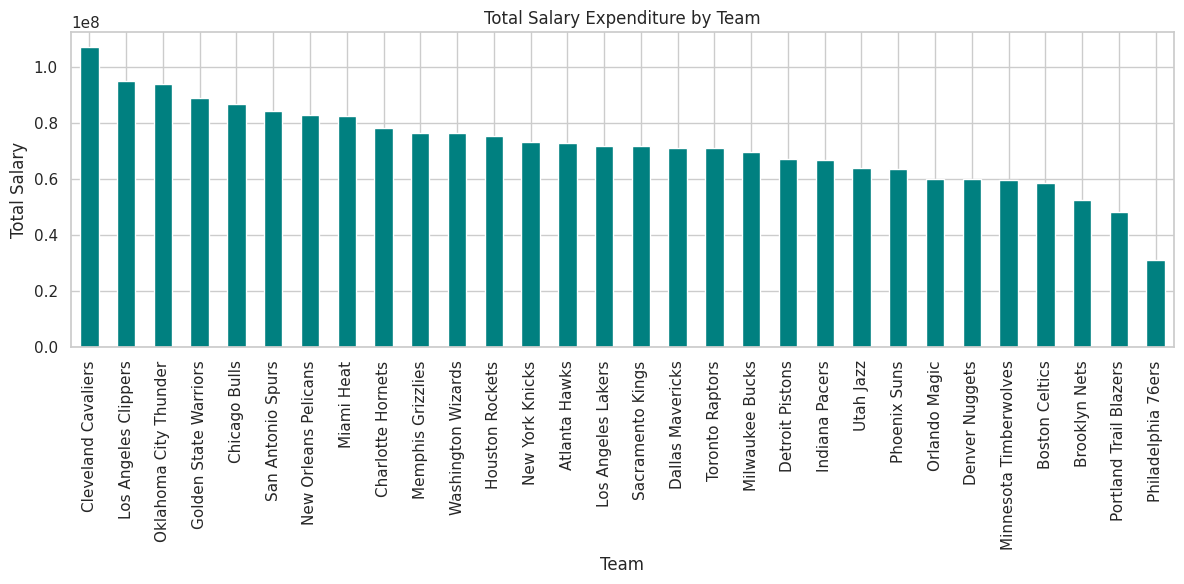

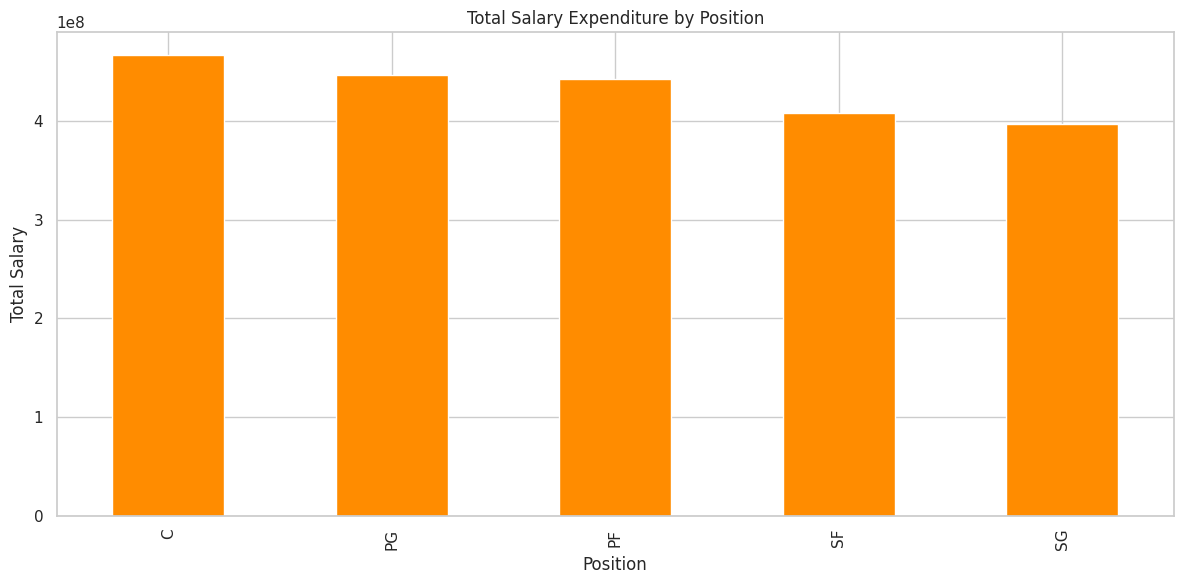

Highest salary expenditure team: Cleveland Cavaliers - 106988689.0
Highest salary expenditure position: C - 466377332.0


In [8]:
team_salary = df.groupby("Team")["Salary"].sum().sort_values(ascending=False)
position_salary = df.groupby("Position")["Salary"].sum().sort_values(ascending=False)
display(team_salary)
display(position_salary)

team_salary.plot(kind="bar", color="teal")
plt.title("Total Salary Expenditure by Team")
plt.xlabel("Team")
plt.ylabel("Total Salary")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

position_salary.plot(kind="bar", color="darkorange")
plt.title("Total Salary Expenditure by Position")
plt.xlabel("Position")
plt.ylabel("Total Salary")
plt.tight_layout()
plt.show()

print("Highest salary expenditure team:", team_salary.idxmax(), "-", team_salary.max())
print("Highest salary expenditure position:", position_salary.idxmax(), "-", position_salary.max())

## 8. Age and Salary Correlation
Calculate the Pearson correlation between Age and Salary and visualize their relationship with a scatterplot and trend line.

Correlation between Age and Salary: 0.214


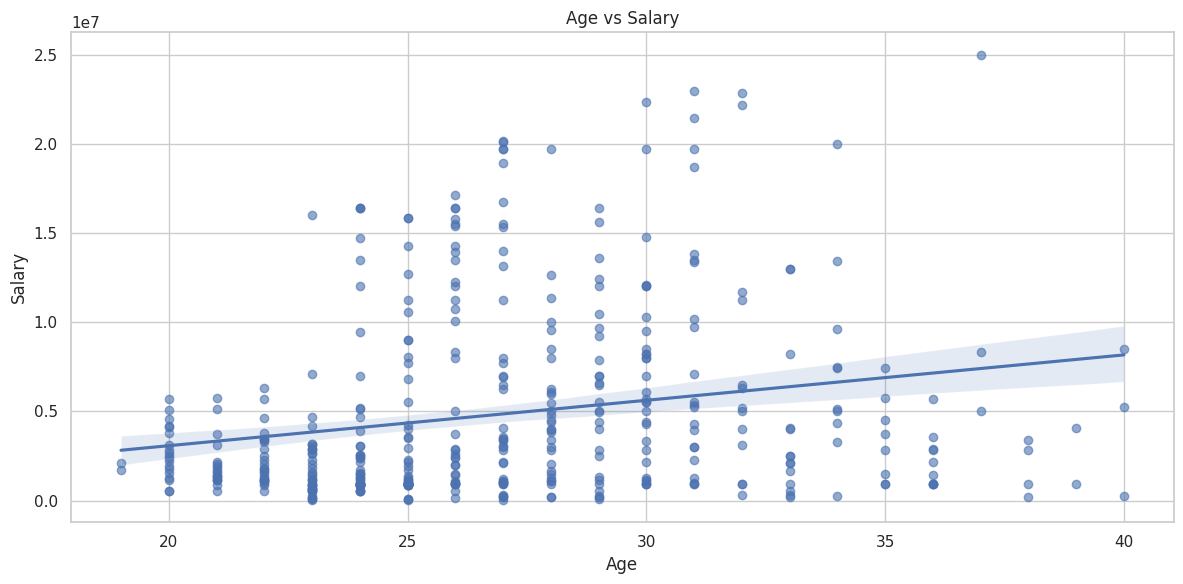

In [9]:
age_salary_corr = df["Age"].corr(df["Salary"])
print("Correlation between Age and Salary:", round(age_salary_corr, 3))

sns.regplot(data=df, x="Age", y="Salary", scatter_kws={"alpha": 0.6})
plt.title("Age vs Salary")
plt.xlabel("Age")
plt.ylabel("Salary")
plt.tight_layout()
plt.show()

## 9. Data Story and Conclusions

1. Employee distribution across teams is relatively balanced, with the New Orleans Pelicans having the highest number of employees.

2. Shooting Guards (SG) are the most common position, followed closely by Power Forwards (PF).

3. The majority of employees fall within the 22–25 age group, indicating a relatively young workforce.

4. The Cleveland Cavaliers have the highest total salary expenditure among teams, while Centers (C) account for the highest salary expenditure among positions.

5. Age and salary show a weak positive correlation (0.21), suggesting that age has a limited relationship with salary.

6. Overall, the dataset shows a balanced team distribution, a young workforce, and varying salary expenditure across teams and positions.